# Exploratory Data Analysis: King County House Sales

**Project:** classify whether the asking price of a house is fair (4 classes) with a Decision Tree.
**Dataset:** Kaggle, *House Sales in King County, USA* (21,613 rows, 21 columns).

This notebook explores the raw data. It does **not** modify, delete or save any data: cleaning is done in `02_data_cleaning.ipynb`, and no row is removed without a joint team decision. Figures are saved to `reports/figures/`.

| Section | Question |
|---|---|
| 1 | What does the dataset contain, and is it complete? |
| 2 | Are there impossible or suspicious values? |
| 3 | How is `price` distributed? |
| 4 | Which variables relate to price? |
| 5 | How much does location matter? |
| 6 | How do time and renovation relate to price? |
| 7 | Where are the outliers? |
| 8 | Which statistical tests support the observations? |

## 0. Setup

This cell imports the libraries required for analysis, defines the dataset and figure paths, configures display settings, and creates a reusable helper for saving plots to the reports folder.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

RANDOM_STATE = 42
RAW_PATH = '../data/raw/usa_house_data.csv'
FIG_DIR = '../reports/figures'
os.makedirs(FIG_DIR, exist_ok=True)

pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', '{:,.2f}'.format)
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.05)
plt.rcParams['figure.dpi'] = 100


def save_fig(name):
    plt.savefig(f'{FIG_DIR}/{name}.png', dpi=150, bbox_inches='tight')

## 1. Dataset overview

This cell loads the raw house sales data, converts the date and zipcode columns into analysis-friendly formats, and creates derived variables that support exploration without altering the original dataset.

In [2]:
df = pd.read_csv(RAW_PATH)
print(f'{df.shape[0]:,} rows x {df.shape[1]} columns')

df['date'] = pd.to_datetime(df['date'], format='%Y%m%dT%H%M%S')
df['zipcode'] = df['zipcode'].astype(str)

# Helper columns for the analysis
df['price_per_sqft'] = df['price'] / df['sqft_living']
df['log_price'] = np.log(df['price'])
df['sale_year'] = df['date'].dt.year
df['sale_month'] = df['date'].dt.to_period('M').dt.to_timestamp()
df['renovated'] = (df['yr_renovated'] != 0).astype(int)

df.head()

21,613 rows x 21 columns


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,price_per_sqft,log_price,sale_year,sale_month,renovated
0,7129300520,2014-10-13,"221,900.00",3,1.00,1180,5650,1.00,0,0,3,7,1180,0,1955,0,98178,47.51,-122.26,1340,5650,188.05,12.31,2014,2014-10-01,0
1,6414100192,2014-12-09,"538,000.00",3,2.25,2570,7242,2.00,0,0,3,7,2170,400,1951,1991,98125,47.72,-122.32,1690,7639,209.34,13.20,2014,2014-12-01,1
2,5631500400,2015-02-25,"180,000.00",2,1.00,770,10000,1.00,0,0,3,6,770,0,1933,0,98028,47.74,-122.23,2720,8062,233.77,12.10,2015,2015-02-01,0
3,2487200875,2014-12-09,"604,000.00",4,3.00,1960,5000,1.00,0,0,5,7,1050,910,1965,0,98136,47.52,-122.39,1360,5000,308.16,13.31,2014,2014-12-01,0
4,1954400510,2015-02-18,"510,000.00",3,2.00,1680,8080,1.00,0,0,3,8,1680,0,1987,0,98074,47.62,-122.05,1800,7503,303.57,13.14,2015,2015-02-01,0


This cell inspects the dataframe schema and confirms the column types, null counts, and structure of the dataset before deeper analysis.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 26 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   id              21613 non-null  int64         
 1   date            21613 non-null  datetime64[us]
 2   price           21613 non-null  float64       
 3   bedrooms        21613 non-null  int64         
 4   bathrooms       21613 non-null  float64       
 5   sqft_living     21613 non-null  int64         
 6   sqft_lot        21613 non-null  int64         
 7   floors          21613 non-null  float64       
 8   waterfront      21613 non-null  int64         
 9   view            21613 non-null  int64         
 10  condition       21613 non-null  int64         
 11  grade           21613 non-null  int64         
 12  sqft_above      21613 non-null  int64         
 13  sqft_basement   21613 non-null  int64         
 14  yr_built        21613 non-null  int64         
 15  yr_renovated 

This cell prints summary statistics for each numeric variable so we can quickly understand the distribution, central tendency, and spread of the housing features.

In [4]:
display(df.describe().T)

,count,mean,min,25%,50%,75%,max,std
id,"21,613.00","4,580,301,520.86","1,000,102.00","2,123,049,194.00","3,904,930,410.00","7,308,900,445.00","9,900,000,190.00","2,876,565,571.31"
date,21613,2014-10-29 04:38:01.959931,2014-05-02 00:00:00,2014-07-22 00:00:00,2014-10-16 00:00:00,2015-02-17 00:00:00,2015-05-27 00:00:00,NaN
price,"21,613.00","540,088.14","75,000.00","321,950.00","450,000.00","645,000.00","7,700,000.00","367,127.20"
bedrooms,"21,613.00",3.37,0.00,3.00,3.00,4.00,33.00,0.93
bathrooms,"21,613.00",2.11,0.00,1.75,2.25,2.50,8.00,0.77
sqft_living,"21,613.00","2,079.90",290.00,"1,427.00","1,910.00","2,550.00","13,540.00",918.44
sqft_lot,"21,613.00","15,106.97",520.00,"5,040.00","7,618.00","10,688.00","1,651,359.00","41,420.51"
floors,"21,613.00",1.49,1.00,1.00,1.50,2.00,3.50,0.54
waterfront,"21,613.00",0.01,0.00,0.00,0.00,0.00,1.00,0.09
view,"21,613.00",0.23,0.00,0.00,0.00,0.00,4.00,0.77


This cell checks overall data quality by summarizing missing values, duplicate records, repeated house IDs, and the time range covered by the sales data.

In [5]:
quality = pd.DataFrame({
    'missing values': [df.isnull().sum().sum()],
    'identical rows': [df.drop(columns=['price_per_sqft', 'log_price', 'sale_year', 'sale_month', 'renovated']).duplicated().sum()],
    'repeated ids (re-sold houses)': [df['id'].duplicated().sum()],
    'distinct zipcodes': [df['zipcode'].nunique()],
    'sale period': [f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}"],
}).T.rename(columns={0: 'value'})
display(quality)

,value
missing values,0
identical rows,0
repeated ids (re-sold houses),177
distinct zipcodes,70
sale period,2014-05-02 to 2015-05-27


## 2. Suspicious values

This section highlights entries that may be invalid, inconsistent, or unusually extreme so they can be reviewed before any cleaning decisions are made.

In [6]:
checks = {
    'price <= 0':                                (df['price'] <= 0).sum(),
    'sqft_living <= 0':                          (df['sqft_living'] <= 0).sum(),
    'bedrooms == 0':                             (df['bedrooms'] == 0).sum(),
    'bathrooms == 0':                            (df['bathrooms'] == 0).sum(),
    'bedrooms >= 10':                            (df['bedrooms'] >= 10).sum(),
    'yr_built > sale year':                      (df['yr_built'] > df['sale_year']).sum(),
    'sqft_above + sqft_basement != sqft_living': ((df['sqft_above'] + df['sqft_basement']) != df['sqft_living']).sum(),
    'yr_renovated == 0 (never renovated)':       (df['yr_renovated'] == 0).sum(),
}
suspicious = pd.DataFrame({'rows': checks})
suspicious['% of data'] = (suspicious['rows'] / len(df) * 100).round(2)
display(suspicious)

,rows,% of data
price <= 0,0,0.00
sqft_living <= 0,0,0.00
bedrooms == 0,13,0.06
bathrooms == 0,10,0.05
bedrooms >= 10,5,0.02
yr_built > sale year,12,0.06
sqft_above + sqft_basement != sqft_living,0,0.00
yr_renovated == 0 (never renovated),20699,95.77


This cell reviews the houses with the highest bedroom counts to identify whether the extreme values are plausible or likely data-quality issues.

In [7]:
# The most extreme bedroom counts, with their living area
display(df.nlargest(5, 'bedrooms')[['id', 'bedrooms', 'bathrooms', 'sqft_living', 'price']])

,id,bedrooms,bathrooms,sqft_living,price
15870,2402100895,33,1.75,1620,"640,000.00"
8757,1773100755,11,3.00,3000,"520,000.00"
13314,627300145,10,5.25,4590,"1,148,000.00"
15161,5566100170,10,2.00,3610,"650,000.00"
19254,8812401450,10,3.00,2920,"660,000.00"


## 3. Distribution of `price`

This section examines the shape of the target variable and checks whether a log transformation improves interpretability and symmetry before modeling.

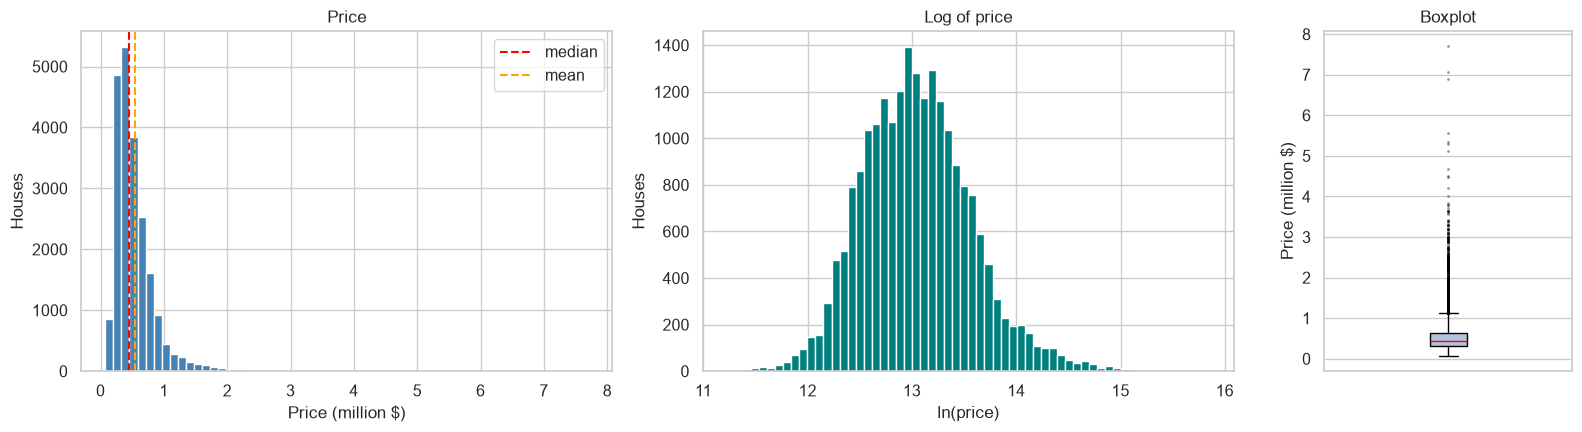

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), gridspec_kw={'width_ratios': [3, 3, 1.4]})

axes[0].hist(df['price'] / 1e6, bins=60, color='steelblue', edgecolor='white')
axes[0].axvline(df['price'].median() / 1e6, color='red', linestyle='--', label='median')
axes[0].axvline(df['price'].mean() / 1e6, color='orange', linestyle='--', label='mean')
axes[0].set(title='Price', xlabel='Price (million $)', ylabel='Houses')
axes[0].legend()

axes[1].hist(df['log_price'], bins=60, color='teal', edgecolor='white')
axes[1].set(title='Log of price', xlabel='ln(price)', ylabel='Houses')

axes[2].boxplot(df['price'] / 1e6, patch_artist=True, boxprops=dict(facecolor='lightsteelblue'),
                medianprops=dict(color='red'), flierprops=dict(marker='.', markersize=2, alpha=0.4))
axes[2].set(title='Boxplot', ylabel='Price (million $)', xticks=[])

plt.tight_layout()
save_fig('01_price_distribution')
plt.show()

This cell quantifies price skewness and compares the raw and log-transformed distributions to support the choice of analysis methods.

In [9]:
price_stats = pd.DataFrame({
    'price': df['price'].describe(percentiles=[.1, .25, .5, .75, .9, .99]),
})
price_stats.loc['skewness'] = [df['price'].skew()]
price_stats.loc['skewness (log price)'] = [df['log_price'].skew()]
display(price_stats)

,price
count,"21,613.00"
mean,"540,088.14"
std,"367,127.20"
min,"75,000.00"
10%,"245,000.00"
25%,"321,950.00"
50%,"450,000.00"
75%,"645,000.00"
90%,"887,000.00"
99%,"1,964,400.00"


## 4. Relationship between variables and price

This section measures how strongly each feature is associated with price using a rank-based correlation approach that is more robust to skewed data and outliers.

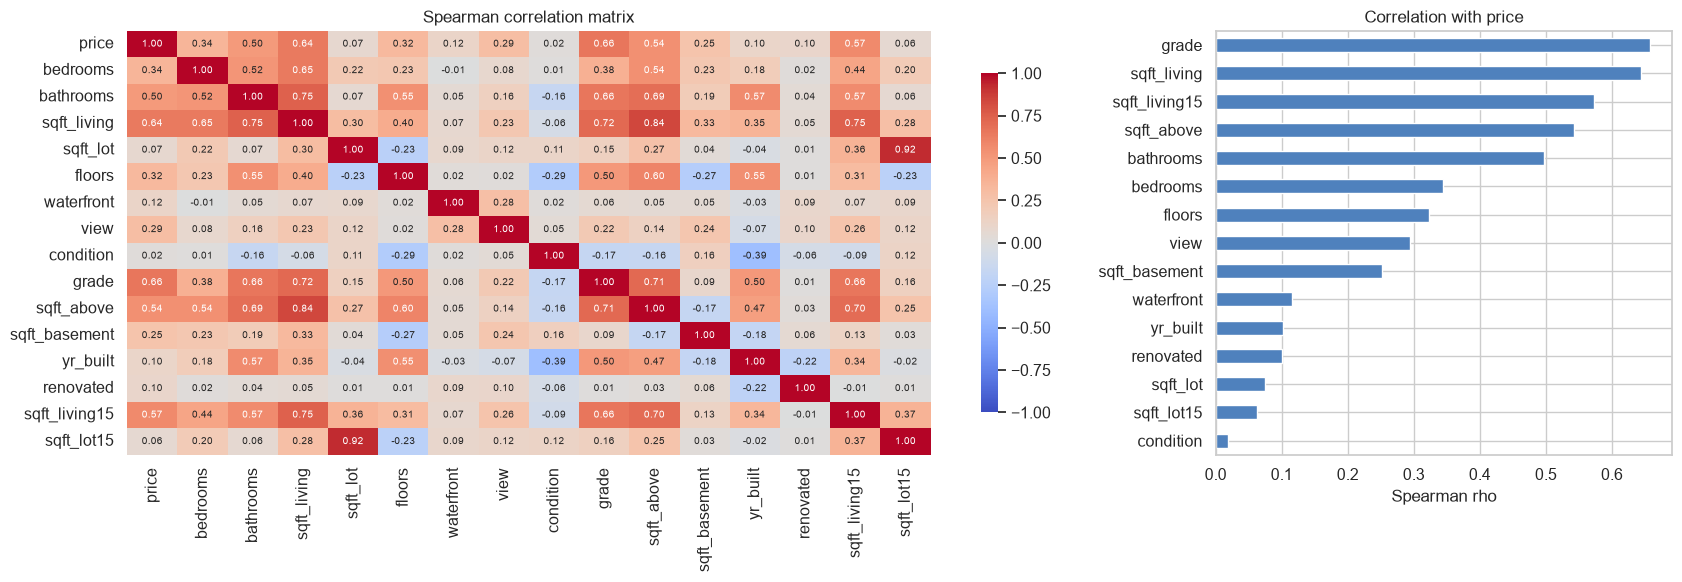

In [10]:
num_cols = ['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront',
            'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'renovated',
            'sqft_living15', 'sqft_lot15']
corr = df[num_cols].corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={'width_ratios': [2.2, 1]})

sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1,
            annot_kws={'size': 7}, cbar_kws={'shrink': 0.8}, ax=axes[0])
axes[0].set_title('Spearman correlation matrix')

price_corr = corr['price'].drop('price').sort_values()
price_corr.plot(kind='barh', ax=axes[1], color=['#c0504d' if v < 0 else '#4f81bd' for v in price_corr])
axes[1].set(title='Correlation with price', xlabel='Spearman rho')

plt.tight_layout()
save_fig('02_spearman_correlations')
plt.show()

This cell visualizes the relationship between living area and sale price, highlighting how size and price-per-square-foot behave across the dataset.

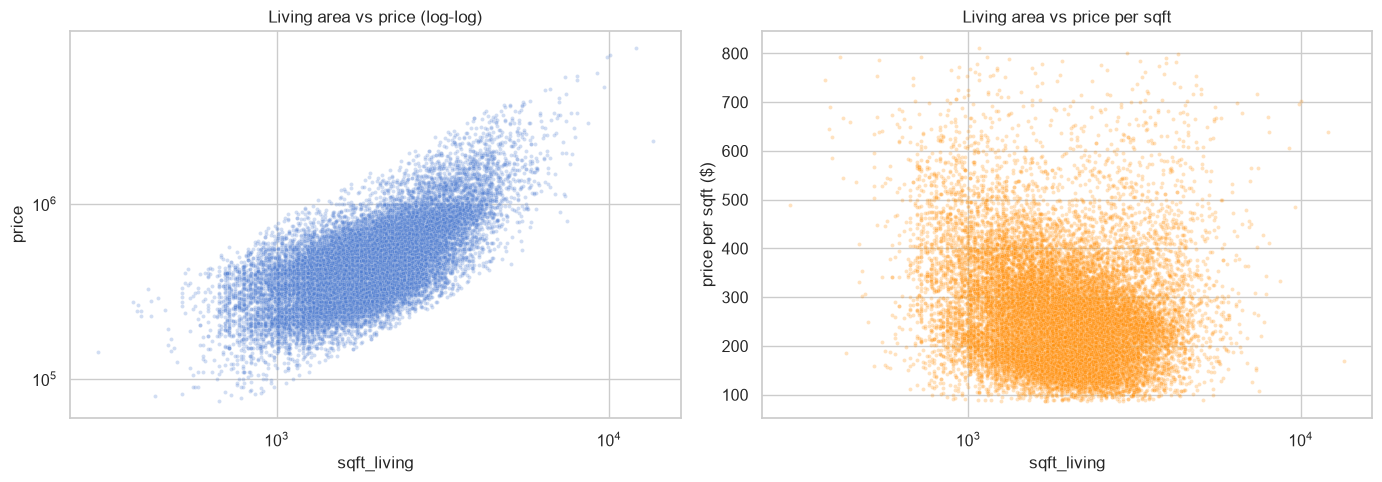

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=df, x='sqft_living', y='price', s=8, alpha=0.25, ax=axes[0])
axes[0].set(xscale='log', yscale='log', title='Living area vs price (log-log)',
            xlabel='sqft_living', ylabel='price')

sns.scatterplot(data=df, x='sqft_living', y='price_per_sqft', s=8, alpha=0.25, ax=axes[1], color='darkorange')
axes[1].set(xscale='log', title='Living area vs price per sqft',
            xlabel='sqft_living', ylabel='price per sqft ($)')

plt.tight_layout()
save_fig('03_area_vs_price')
plt.show()

This cell compares price across categorical and ordinal features such as grade, condition, view, and bedroom groupings to understand which property characteristics drive value.

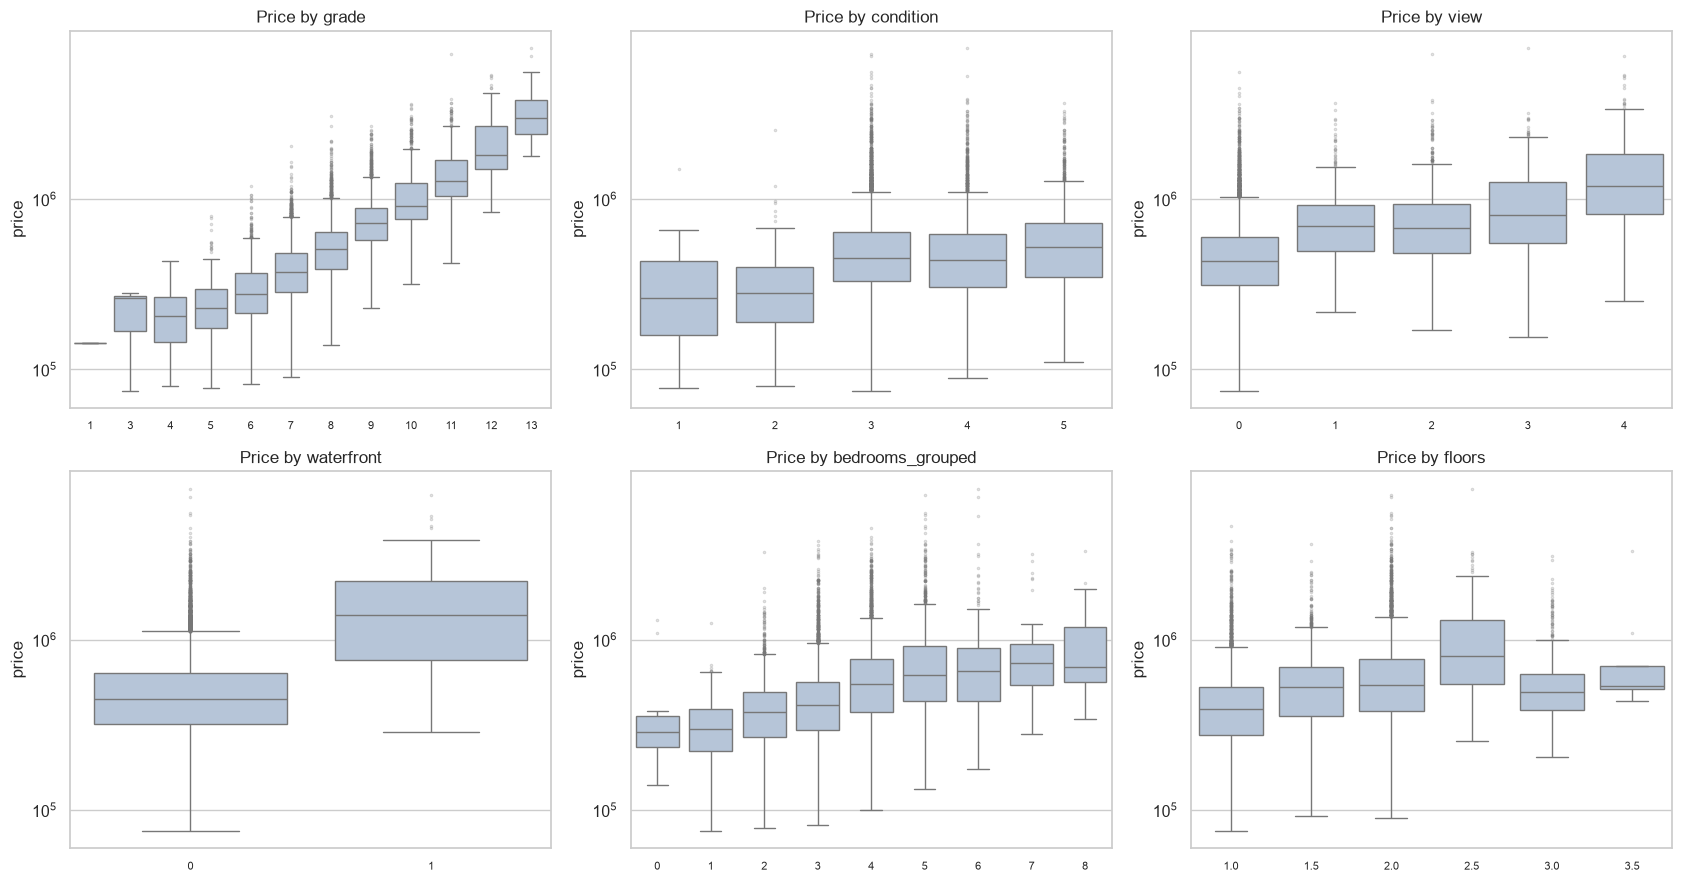

In [12]:
df['bedrooms_grouped'] = df['bedrooms'].clip(upper=8)   # 8 means 8 or more
cat_cols = ['grade', 'condition', 'view', 'waterfront', 'bedrooms_grouped', 'floors']

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, col in zip(axes.ravel(), cat_cols):
    sns.boxplot(data=df, x=col, y='price', ax=ax, color='lightsteelblue',
                fliersize=1.5, flierprops=dict(alpha=0.3))
    ax.set_yscale('log')
    ax.set_title(f'Price by {col}')
    ax.set_xlabel('')
    ax.tick_params(axis='x', labelsize=8)

plt.tight_layout()
save_fig('04_price_by_category')
plt.show()
df.drop(columns='bedrooms_grouped', inplace=True)

## 5. Location: `zipcode`

This section evaluates how median price per square foot varies by zipcode so the notebook can isolate the effect of location from raw house size.

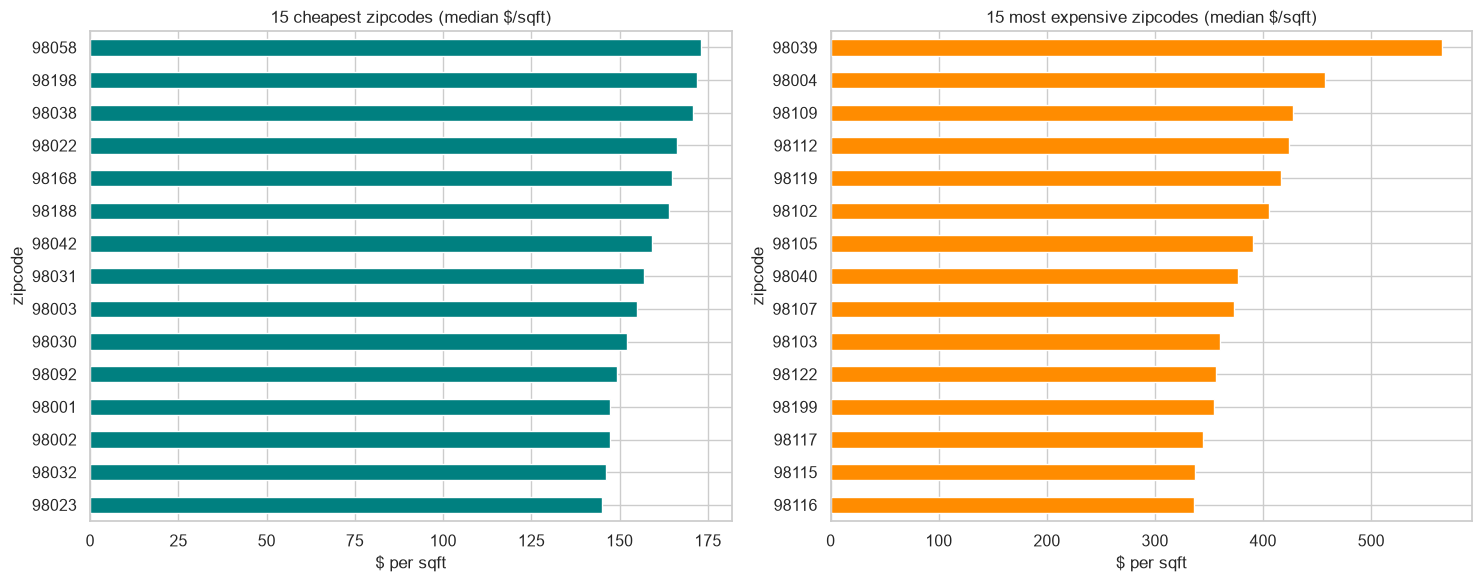

Most expensive vs cheapest zipcode (median $/sqft): x3.9


In [13]:
zip_stats = (df.groupby('zipcode')
               .agg(sales=('price', 'size'),
                    median_price=('price', 'median'),
                    median_ppsf=('price_per_sqft', 'median'))
               .query('sales >= 20')
               .sort_values('median_ppsf'))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
zip_stats['median_ppsf'].head(15).plot(kind='barh', ax=axes[0], color='teal')
axes[0].set(title='15 cheapest zipcodes (median $/sqft)', xlabel='$ per sqft', ylabel='zipcode')
zip_stats['median_ppsf'].tail(15).plot(kind='barh', ax=axes[1], color='darkorange')
axes[1].set(title='15 most expensive zipcodes (median $/sqft)', xlabel='$ per sqft', ylabel='zipcode')

plt.tight_layout()
save_fig('05_zipcode_price_per_sqft')
plt.show()

ratio = zip_stats['median_ppsf'].max() / zip_stats['median_ppsf'].min()
print(f'Most expensive vs cheapest zipcode (median $/sqft): x{ratio:.1f}')

This cell plots a geographic overview of the houses and color-codes each sale by log price to visualize whether pricing patterns are spatially clustered.

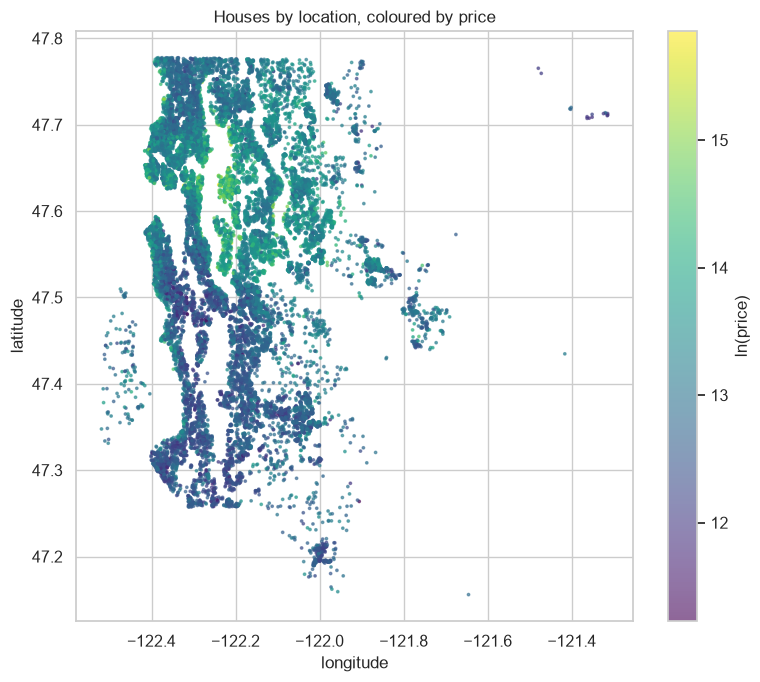

In [14]:
# Geographic view (exploration only: lat and long are not used as model inputs)
fig, ax = plt.subplots(figsize=(8, 7))
sc = ax.scatter(df['long'], df['lat'], c=df['log_price'], s=3, cmap='viridis', alpha=0.6)
plt.colorbar(sc, label='ln(price)')
ax.set(title='Houses by location, coloured by price', xlabel='longitude', ylabel='latitude')

plt.tight_layout()
save_fig('06_price_map')
plt.show()

## 6. Time and renovation

This section examines how sale timing, construction age, and renovation status appear to influence housing prices.

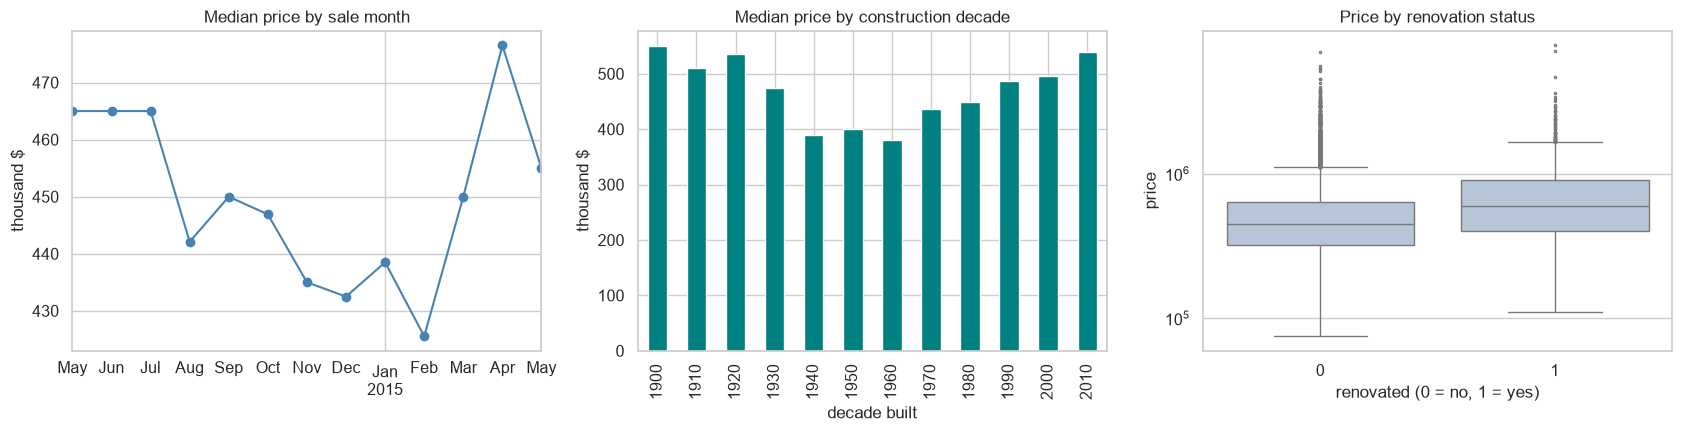

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

monthly = df.groupby('sale_month')['price'].median() / 1e3
monthly.plot(ax=axes[0], marker='o', color='steelblue')
axes[0].set(title='Median price by sale month', xlabel='', ylabel='thousand $')

df.assign(decade=(df['yr_built'] // 10 * 10)).groupby('decade')['price'].median().div(1e3).plot(
    kind='bar', ax=axes[1], color='teal')
axes[1].set(title='Median price by construction decade', xlabel='decade built', ylabel='thousand $')

sns.boxplot(data=df, x='renovated', y='price', ax=axes[2], color='lightsteelblue', fliersize=1.5)
axes[2].set(yscale='log', title='Price by renovation status', xlabel='renovated (0 = no, 1 = yes)')

plt.tight_layout()
save_fig('07_time_and_renovation')
plt.show()

## 7. Outliers

This section identifies extreme observations using the IQR rule and separates statistical outliers from genuine luxury properties that may deserve special review.

In [16]:
outlier_cols = ['price', 'sqft_living', 'sqft_lot', 'bedrooms', 'bathrooms', 'price_per_sqft']
rows = []
for col in outlier_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < lo) | (df[col] > hi)).sum()
    rows.append({'column': col, 'Q1': q1, 'Q3': q3, 'lower bound': lo, 'upper bound': hi,
                 'outliers': n_out, '% of data': n_out / len(df) * 100})
outliers = pd.DataFrame(rows).set_index('column')
display(outliers)

,Q1,Q3,lower bound,upper bound,outliers,% of data
column,,,,,,
price,"321,950.00","645,000.00","-162,625.00","1,129,575.00",1146,5.30
sqft_living,"1,427.00","2,550.00",-257.50,"4,234.50",572,2.65
sqft_lot,"5,040.00","10,688.00","-3,432.00","19,160.00",2425,11.22
bedrooms,3.00,4.00,1.50,5.50,546,2.53
bathrooms,1.75,2.50,0.62,3.62,571,2.64
price_per_sqft,182.29,318.32,-21.76,522.37,708,3.28


This cell displays the outlier counts for the most relevant numeric features to understand how much of the data falls outside the expected range.

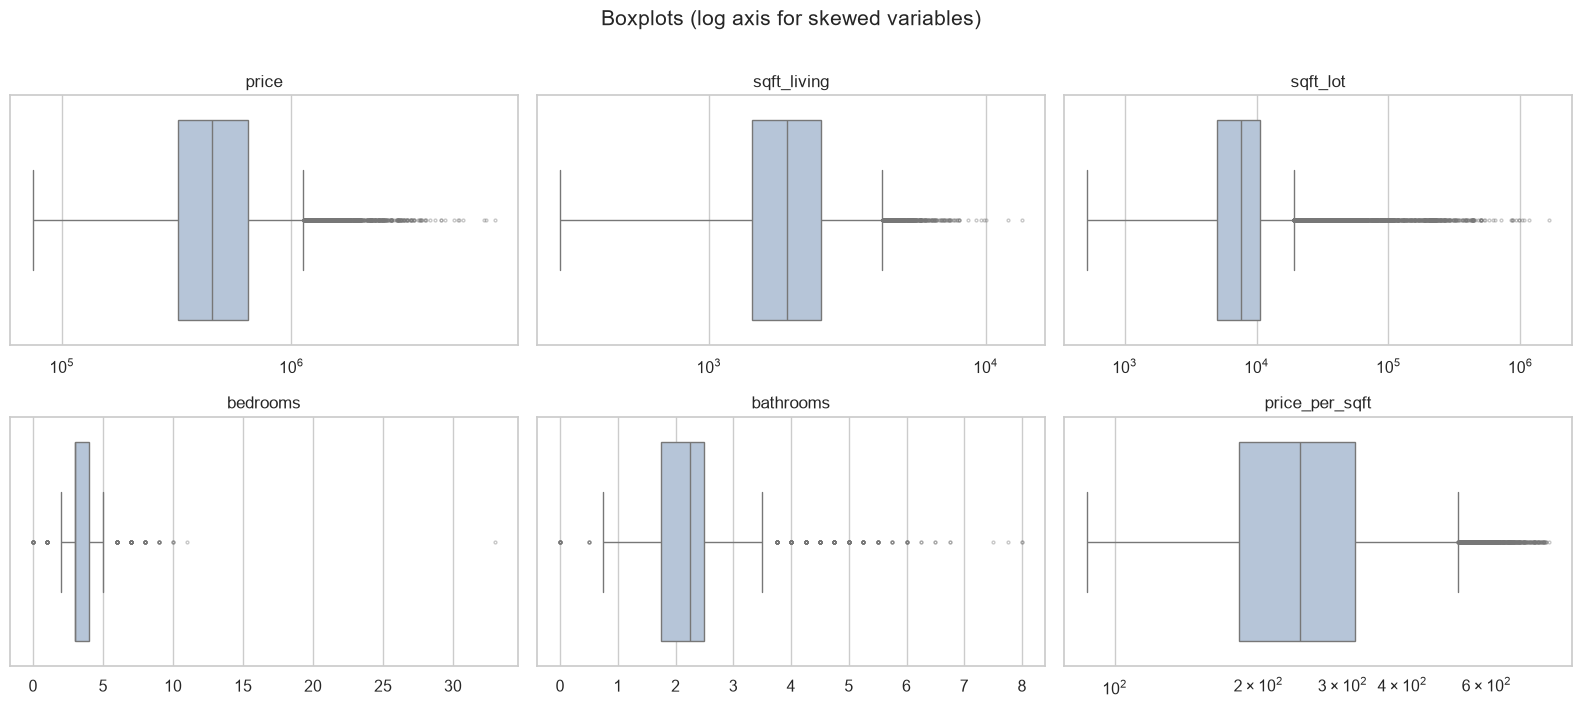

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, col in zip(axes.ravel(), outlier_cols):
    sns.boxplot(x=df[col], ax=ax, color='lightsteelblue', fliersize=2, flierprops=dict(alpha=0.4))
    ax.set_title(col)
    ax.set_xlabel('')
    if col in ('price', 'sqft_lot', 'sqft_living', 'price_per_sqft'):
        ax.set_xscale('log')

plt.suptitle('Boxplots (log axis for skewed variables)', y=1.01)
plt.tight_layout()
save_fig('08_outlier_boxplots')
plt.show()

This cell compares the most expensive houses against the rest of the dataset to assess whether the outliers are structurally different or simply represent upscale properties.

In [18]:
# Are the price outliers plausible? Compare them with the rest of the data
q1, q3 = df['price'].quantile([0.25, 0.75])
price_out = df['price'] > q3 + 1.5 * (q3 - q1)

profile = pd.DataFrame({
    'price outliers': df[price_out][['sqft_living', 'grade', 'waterfront', 'view']].mean(),
    'other houses':   df[~price_out][['sqft_living', 'grade', 'waterfront', 'view']].mean(),
})
display(profile)
print('Most expensive houses:')
display(df.nlargest(5, 'price')[['price', 'sqft_living', 'grade', 'waterfront', 'view', 'zipcode']])

,price outliers,other houses
sqft_living,"3,943.39","1,975.56"
grade,9.91,7.53
waterfront,0.09,0.00
view,1.34,0.17


Most expensive houses:


,price,sqft_living,grade,waterfront,view,zipcode
7252,"7,700,000.00",12050,13,0,3,98102
3914,"7,062,500.00",10040,11,1,2,98004
9254,"6,885,000.00",9890,13,0,4,98039
4411,"5,570,000.00",9200,13,0,0,98039
1448,"5,350,000.00",8000,12,0,4,98004


## 8. Statistical tests

This section selects the most appropriate non-parametric tests for skewed housing data and documents the reasoning behind each test before interpreting the p-values.

### 8.1 Normality of price (Shapiro-Wilk)

This cell tests whether price and its log transform are approximately normal, which helps determine whether parametric or non-parametric methods are appropriate.

,W,p-value,normal at 5%
variable,,,
price,0.70,0.00,False
ln(price),0.99,0.00,False


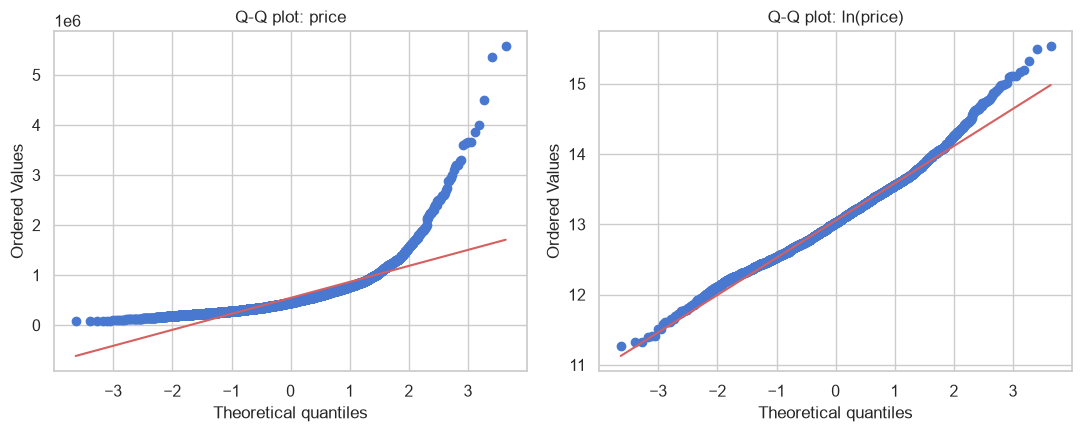

In [19]:
sample = df.sample(n=min(5000, len(df)), random_state=RANDOM_STATE)

results = []
for name, series in [('price', sample['price']), ('ln(price)', sample['log_price'])]:
    w, p = stats.shapiro(series)
    results.append({'variable': name, 'W': w, 'p-value': p, 'normal at 5%': p > 0.05})
display(pd.DataFrame(results).set_index('variable'))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
stats.probplot(sample['price'], dist='norm', plot=axes[0])
axes[0].set_title('Q-Q plot: price')
stats.probplot(sample['log_price'], dist='norm', plot=axes[1])
axes[1].set_title('Q-Q plot: ln(price)')
plt.tight_layout()
save_fig('09_qq_plots')
plt.show()

### 8.2 Spearman correlation with price

This cell calculates rank-based correlations between price and the strongest numeric predictors to quantify which variables move together most consistently.

In [20]:
test_cols = ['sqft_living', 'grade', 'sqft_above', 'bathrooms', 'view', 'bedrooms',
             'sqft_lot', 'condition', 'yr_built']
rows = []
for col in test_cols:
    rho, p = stats.spearmanr(df[col], df['price'])
    rows.append({'variable': col, 'rho': rho, 'p-value': p})
spearman = pd.DataFrame(rows).set_index('variable').sort_values('rho', ascending=False)
display(spearman)

,rho,p-value
variable,,
grade,0.66,0.00
sqft_living,0.64,0.00
sqft_above,0.54,0.00
bathrooms,0.50,0.00
bedrooms,0.34,0.00
view,0.29,0.00
yr_built,0.10,0.00
sqft_lot,0.07,0.00
condition,0.02,0.01


### 8.3 Mann-Whitney U: price between two groups

This cell compares price differences between two groups using a non-parametric test that avoids the normality assumption required by parametric alternatives.

In [21]:
def mann_whitney(col):
    a = df.loc[df[col] == 1, 'price']
    b = df.loc[df[col] == 0, 'price']
    u, p = stats.mannwhitneyu(a, b, alternative='two-sided')
    return {'variable': col, 'n (=1)': len(a), 'n (=0)': len(b),
            'median price (=1)': a.median(), 'median price (=0)': b.median(),
            'U': u, 'p-value': p, 'rank-biserial r': 2 * u / (len(a) * len(b)) - 1}

mw = pd.DataFrame([mann_whitney('waterfront'), mann_whitney('renovated')]).set_index('variable')
display(mw)

,n (=1),n (=0),median price (=1),median price (=0),U,p-value,rank-biserial r
variable,,,,,,,
waterfront,163,21450,"1,400,000.00","450,000.00","3,090,831.00",0.00,0.77
renovated,914,20699,"600,000.00","448,000.00","12,201,046.50",0.00,0.29


### 8.4 Kruskal-Wallis: price across groups

This cell compares price across multiple groups using a non-parametric ANOVA-style method to test whether location or quality categories produce different price distributions.

In [22]:
def kruskal(col):
    groups = [g['price'].values for _, g in df.groupby(col)]
    h, p = stats.kruskal(*groups)
    k, n = len(groups), len(df)
    return {'grouping': col, 'groups': k, 'H': h, 'p-value': p, 'epsilon-squared': (h - k + 1) / (n - k)}

kw = pd.DataFrame([kruskal('grade'), kruskal('zipcode'), kruskal('condition')]).set_index('grouping')
display(kw)

,groups,H,p-value,epsilon-squared
grouping,,,,
grade,12,"9,694.85",0.00,0.45
zipcode,70,"12,101.60",0.00,0.56
condition,5,260.85,0.00,0.01


## 9. Summary of results

This cell consolidates the main findings from the exploratory analysis into a concise final overview that sets up the cleaning and modeling stages.

In [23]:
top = spearman.index[0]
summary = pd.Series({
    'Houses': f'{len(df):,}',
    'Missing values': int(df.isnull().sum().sum()),
    'Median price': f"${df['price'].median():,.0f}",
    'Skewness of price / ln(price)': f"{df['price'].skew():.2f} / {df['log_price'].skew():.2f}",
    'Variable most correlated with price': f"{top} (rho = {spearman.loc[top, 'rho']:.2f})",
    'Median $/sqft, most vs least expensive zipcode': f'x{ratio:.1f}',
    'IQR price outliers': f"{int(outliers.loc['price', 'outliers']):,} ({outliers.loc['price', '% of data']:.1f}%)",
    'Price differs by waterfront (Mann-Whitney)': 'yes' if mw.loc['waterfront', 'p-value'] < 0.05 else 'no',
    'Price differs by zipcode (Kruskal-Wallis)': 'yes' if kw.loc['zipcode', 'p-value'] < 0.05 else 'no',
}, name='result')
display(summary.to_frame())

,result
Houses,"21,613"
Missing values,0
Median price,"$450,000"
Skewness of price / ln(price),4.02 / 0.43
Variable most correlated with price,grade (rho = 0.66)
"Median $/sqft, most vs least expensive zipcode",x3.9
IQR price outliers,"1,146 (5.3%)"
Price differs by waterfront (Mann-Whitney),yes
Price differs by zipcode (Kruskal-Wallis),yes


### Points carried to the next stages

- `price` is strongly right-skewed and not normal, so rank-based methods are used and the log scale is used for plots.
- Size and quality variables (`sqft_living`, `grade`) and `zipcode` are the main drivers of price; `zipcode` is categorical.
- `yr_renovated` is mostly 0 and should become a yes/no flag.
- Suspicious rows (33 bedrooms, houses with 0 bedrooms and 0 bathrooms) are handled in the cleaning notebook.
- IQR outliers are reported but nothing is removed: treatment is a joint decision.
- `id`, `date`, `lat`, `long` and the `*15` columns are used for exploration only and are not inputs of the web form.